# 09_selector_calibration.ipynb

Task 5.3, hiệu chỉnh ngưỡng của bộ chọn xử lý ảnh thích ứng trên **validation**. Đặc tả ở `docs/task-5.1-selector-design.md`, cấu hình ở `configs/selector.yaml`, code ở `src/selector/`.

Reference model Swin-Tiny đóng băng. Với ảnh sạch và 42 điều kiện của benchmark 4.1, notebook tính đặc trưng chất lượng và dự đoán cho từng hành động (giữ nguyên, unsharp, bilateral), rồi tìm ngưỡng của luật trên bảng đó. Hai giai đoạn trong một phiên:

- **A (GPU):** thu thập đặc trưng và dự đoán. Mục này lâu nhất.
- **B (CPU):** tìm ngưỡng, báo cáo, kiểm tra độ ổn định bằng cross-validation theo ảnh.

Không mở tập test. Kết quả ghi vào `reports/selector/`, `locked` là `false` cho tới khi nhóm xem lại và khóa.

## 1. Môi trường

Internet để On. Accelerator chọn GPU (T4). Dataset input cần hai cái: `cthng123/durian-leaf-disease-dataset` và dataset chứa checkpoint `swin_tiny_seed42.pt` (cùng dataset đã dùng cho notebook 08).

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# Đổi nhánh tại đây, rồi chạy lại cell.
GIT_BRANCH = "adaptive-selector"
REPO_URL = "https://github.com/meo225/durian-leaf-disease-robustness.git"
REPO_DIR = Path("/kaggle/working") / "durian-leaf-disease-robustness"

if not (Path("/kaggle/working").is_dir() and Path("/kaggle/input").is_dir()):
    raise RuntimeError("Notebook này chỉ chạy trên Kaggle. Xem README, mục Chạy trên Kaggle.")

def git(args, cwd=None):
    subprocess.run(
        ["git", *args],
        cwd=cwd,
        check=True,
        env={**os.environ, "GIT_TERMINAL_PROMPT": "0"},
    )


if not (REPO_DIR / ".git").is_dir():
    git(["clone", "--branch", GIT_BRANCH, "--single-branch", REPO_URL, str(REPO_DIR)])
else:
    git(["fetch", "origin", GIT_BRANCH], cwd=REPO_DIR)
    git(["checkout", GIT_BRANCH], cwd=REPO_DIR)
    git(["reset", "--hard", f"origin/{GIT_BRANCH}"], cwd=REPO_DIR)

matches = []
seen = set()
for path in Path("/kaggle/input").rglob("DLD_FinalDataset_224_spit"):
    resolved = str(path.resolve())
    if path.is_dir() and resolved not in seen:
        seen.add(resolved)
        matches.append(path)

if not matches:
    found = []
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for path in sorted(input_root.rglob("*")):
            if path.is_dir() and len(path.relative_to(input_root).parts) <= 3:
                found.append(str(path.relative_to(input_root)))
    listing = "\n".join(found[:40]) if found else "(trống)"
    raise FileNotFoundError(
        "Chưa thấy DLD_FinalDataset_224_spit trong /kaggle/input.\n"
        "Add Input: cthng123/durian-leaf-disease-dataset, rồi Save & Run All.\n"
        f"Thư mục hiện có:\n{listing}"
    )

image_root = matches[0].parent
link = REPO_DIR / "datasets" / "durian-ldd"
link.parent.mkdir(parents=True, exist_ok=True)
if link.is_symlink() or link.is_file():
    link.unlink()
elif link.exists():
    link.rmdir()
link.symlink_to(image_root, target_is_directory=True)

if not (link / "DLD_FinalDataset_224_spit").is_dir():
    raise FileNotFoundError(f"Không thấy ảnh tại {link}")

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

commit = subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"], cwd=REPO_DIR, text=True
).strip()
branch = subprocess.check_output(
    ["git", "branch", "--show-current"], cwd=REPO_DIR, text=True
).strip()
print(f"Nhánh: {branch}")
print(f"Commit: {commit}")
print(f"Ảnh: {link / 'DLD_FinalDataset_224_spit'}")

Cloning into '/kaggle/working/durian-leaf-disease-robustness'...


Nhánh: adaptive-selector
Commit: bb7cd5e
Ảnh: /kaggle/working/durian-leaf-disease-robustness/datasets/durian-ldd/DLD_FinalDataset_224_spit


## 2. Cấu hình, checkpoint và dữ liệu

Kiểm tra GPU, đọc cấu hình, nạp reference model. Thiếu GPU thì dừng ngay.

In [2]:
import json
import os
import time

import cv2
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Image, display

from src.corruption import load_conditions, load_seed
from src.evaluation.processing_benchmark import ImageCache
from src.evaluation.reference import collect_checkpoint, load_trained_model
from src.selector.calibrate import CalibrationTable, Settings, collect, cross_validate, fit, report, save_artifacts
from src.selector.pipeline import load_selector_config
from src.selector.plots import plot_by_family
from src.training.loop import resolve_device

CONFIG = "configs/selector.yaml"
cfg = load_selector_config(CONFIG)
settings = Settings.from_config(cfg["calibration"])
pipeline_cfg = yaml.safe_load((REPO_DIR / "configs/pipeline.yaml").read_text(encoding="utf-8"))
classes = list(pipeline_cfg["classes"])
RES = REPO_DIR / "outputs/results/selector"
REP = REPO_DIR / cfg["output_dir"]
for folder in (RES, REP):
    folder.mkdir(parents=True, exist_ok=True)

assert cfg["split"] == "val", "Hiệu chỉnh chỉ dùng validation."
assert os.environ.get("FINAL_EVAL") != "1", "FINAL_EVAL đang bật. Hiệu chỉnh không được mở tập test."

device = resolve_device()
if device.type != "cuda":
    raise RuntimeError("Notebook này cần GPU. Trong Session options chọn Accelerator GPU, rồi chạy lại từ cell đầu.")
# Bộ lọc OpenCV giải phóng GIL nên chạy song song bằng luồng. Mỗi luồng dùng một nhân để khỏi tranh nhau.
WORKERS = max(1, min(8, os.cpu_count() or 1))
cv2.setNumThreads(1)

reference = json.loads((REPO_DIR / "reports/baselines/reference_final.json").read_text(encoding="utf-8"))["selection"]["reference"]
assert reference == "swin_tiny", f"Reference model là {reference}, notebook này viết cho swin_tiny."
train_cfg = yaml.safe_load((REPO_DIR / cfg["train_config"]).read_text(encoding="utf-8"))
checkpoint = collect_checkpoint("/kaggle/input", cfg["checkpoint_name"], "/kaggle/working/checkpoints")
model = load_trained_model(train_cfg, checkpoint, len(classes), device)

seed = load_seed(cfg["corruption_config"])
conditions = load_conditions(cfg["corruption_config"], cfg["split"])
cache = ImageCache(pipeline_cfg, conditions, seed, split=cfg["split"])
print(f"Thiết bị: {device}, reference: {reference}, số luồng lọc ảnh: {WORKERS}")
print(f"{len(cache)} ảnh {cfg['split']}, {len(conditions)} điều kiện, hành động: {', '.join(cfg['actions'])}")

Thiết bị: cuda, reference: swin_tiny, số luồng lọc ảnh: 4
444 ảnh val, 42 điều kiện, hành động: keep, unsharp_strong, unsharp_mild, bilateral_wide, bilateral_narrow


## 3. Giai đoạn A: đặc trưng và dự đoán cho từng hành động

Với mỗi điều kiện, ảnh suy giảm tạo một lần. Đặc trưng tính trên ảnh chưa xử lý, rồi reference model chạy trên ảnh sau mỗi hành động. Bảng lưu sau mỗi điều kiện, nên nếu phiên bị ngắt vẫn còn bản dở dang trong `outputs/results/selector/`.

In [3]:
start = time.time()
partial = RES / "calibration_table_val_partial.npz"


def progress(message):
    print(f"[{(time.time() - start) / 60:5.1f} phút] {message}", flush=True)


table = collect(
    model, cache, conditions, cfg["actions"], pipeline_cfg, device,
    workers=WORKERS, progress=progress, on_condition_done=lambda part: part.save(partial),
)
table_path = RES / "calibration_table_val.npz"
table.save(table_path)
partial.unlink(missing_ok=True)
print(f"Giai đoạn A xong sau {(time.time() - start) / 60:.1f} phút: {len(table.conditions)} điều kiện, {len(table.actions)} hành động")
print(f"Đã lưu {table_path} ({table_path.stat().st_size / 1024**2:.1f} MB)")

[  0.3 phút] clean: 444 ảnh, 5 hành động
[  0.5 phút] brightness_dark_s1: 444 ảnh, 5 hành động
[  0.8 phút] brightness_dark_s2: 444 ảnh, 5 hành động
[  1.1 phút] brightness_dark_s3: 444 ảnh, 5 hành động
[  1.4 phút] brightness_bright_s1: 444 ảnh, 5 hành động
[  1.7 phút] brightness_bright_s2: 444 ảnh, 5 hành động
[  2.0 phút] brightness_bright_s3: 444 ảnh, 5 hành động
[  2.3 phút] contrast_low_s1: 444 ảnh, 5 hành động
[  2.6 phút] contrast_low_s2: 444 ảnh, 5 hành động
[  2.9 phút] contrast_low_s3: 444 ảnh, 5 hành động
[  3.2 phút] blur_s1: 444 ảnh, 5 hành động
[  3.5 phút] blur_s2: 444 ảnh, 5 hành động
[  3.8 phút] blur_s3: 444 ảnh, 5 hành động
[  4.1 phút] noise_s1: 444 ảnh, 5 hành động
[  4.4 phút] noise_s2: 444 ảnh, 5 hành động
[  4.7 phút] noise_s3: 444 ảnh, 5 hành động
[  5.0 phút] contrast_high_s1: 444 ảnh, 5 hành động
[  5.2 phút] contrast_high_s2: 444 ảnh, 5 hành động
[  5.5 phút] contrast_high_s3: 444 ảnh, 5 hành động
[  5.8 phút] glare_s1: 444 ảnh, 5 hành động
[  6.1 phút] gl

### Kiểm tra bảng

Dự đoán `keep` ở ảnh sạch và các điều kiện phải khớp điểm của reference trên validation (task 4.2, `reports/sensitivity/sensitivity_conditions_val.csv`).

In [4]:
from src.selector.calibrate import score

reference_val = pd.read_csv(REPO_DIR / "reports/sensitivity/sensitivity_conditions_val.csv")
none = score(table, np.zeros((len(table.conditions), len(table.labels)), dtype=np.int64))
ours = pd.DataFrame({"condition": table.conditions, "f1_table": none})
merged = ours.merge(reference_val[["condition", "macro_f1"]], on="condition", how="left")
merged["diff"] = (merged["f1_table"] - merged["macro_f1"]).abs()
print(f"Lệch lớn nhất so với task 4.2: {merged['diff'].max():.4f} (kỳ vọng dưới 0,01, do làm tròn xác suất)")
display(merged.sort_values("diff", ascending=False).head(5).round(4))

Lệch lớn nhất so với task 4.2: 0.0000 (kỳ vọng dưới 0,01, do làm tròn xác suất)


,condition,f1_table,macro_f1,diff
2,brightness_dark_s2,0.9249,0.9249,0.0
4,brightness_bright_s1,0.9361,0.9361,0.0
10,blur_s1,0.9577,0.9577,0.0
7,contrast_low_s1,0.9619,0.9619,0.0
28,motion_blur_s1,0.9210,0.9210,0.0


## 4. Giai đoạn B: tìm ngưỡng

Mục tiêu là macro F1 trung bình 42 điều kiện trên validation, với ràng buộc trên ảnh sạch (giảm F1 tối đa và tỉ lệ kích hoạt tối đa, xem `configs/selector.yaml`). Luật nào không tăng mục tiêu ít nhất `min_gain` thì bị bỏ; không luật nào đáng giữ là kết quả âm hợp lệ.

In [5]:
selector, search_log = fit(table, cfg["rules"], settings)
frame, summary = report(table, selector)
print("Luật được giữ:")
for rule in selector.rules:
    print(f"  {rule.name}: {' VÀ '.join(f'{c.feature} {c.op} {c.threshold:.4g}' for c in rule.clauses)} -> {rule.action}")
if not selector.rules:
    print("  (không có: bộ chọn luôn giữ nguyên ảnh)")
for entry in search_log["rules"]:
    status = "giữ" if entry["accepted"] else f"bỏ ({entry.get('reason', '')})"
    print(f"- {entry['name']}: {status}; đã chấm {entry['evaluated']} bộ ngưỡng")
print()
print(f"Mục tiêu (TB 42 điều kiện): không xử lý {summary['objective_none']:.4f} -> bộ chọn {summary['objective_selector']:.4f} ({summary['gain']:+.4f})")
print(f"F1 ảnh sạch: {summary['clean_f1_none']:.4f} -> {summary['clean_f1_selector']:.4f}; tỉ lệ kích hoạt trên ảnh sạch {summary['clean_trigger_rate']:.3f}")
print(f"Tốt hơn / kém hơn không xử lý: {summary['conditions_better']} / {summary['conditions_worse']} điều kiện")
print(f"Cận trên theo ảnh (dùng nhãn, không triển khai được): {summary['image_level_upper_bound']:.4f}")
display(pd.Series(summary["fixed_action_objective"], name="TB 42 điều kiện khi cố định một hành động").round(4).to_frame())

Luật được giữ:
  noise: noise_sigma >= 0.01062 VÀ luma_mean >= 0.3078 -> bilateral_wide
  blur: mscn_var <= 0.18 VÀ noise_sigma <= 0.003391 -> unsharp_strong
- noise: giữ; đã chấm 1020 bộ ngưỡng
- blur: giữ; đã chấm 1430 bộ ngưỡng

Mục tiêu (TB 42 điều kiện): không xử lý 0.8607 -> bộ chọn 0.8802 (+0.0195)
F1 ảnh sạch: 0.9664 -> 0.9664; tỉ lệ kích hoạt trên ảnh sạch 0.011
Tốt hơn / kém hơn không xử lý: 25 / 7 điều kiện
Cận trên theo ảnh (dùng nhãn, không triển khai được): 0.9209


,TB 42 điều kiện khi cố định một hành động
keep,0.8607
unsharp_strong,0.7471
unsharp_mild,0.8393
bilateral_wide,0.8285
bilateral_narrow,0.8402


### Độ ổn định

Hiệu chỉnh trên phần ảnh còn lại và chấm trên phần giữ lại, chia theo lớp. Nếu mức tăng giữ lại gần mức tăng trên tập hiệu chỉnh và ngưỡng ít đổi giữa các phần thì ngưỡng ổn định. Lưu ý các họ suy giảm vẫn là các họ đã thấy; tổng quát hóa sang họ chưa thấy đo ở task 5.5 và 6.1.

In [6]:
stability = cross_validate(table, cfg["rules"], settings, folds=int(cfg["calibration"]["cv_folds"]), seed=seed)
print(f"Mức tăng trên phần giữ lại: {stability['heldout_gain_mean']:+.4f} ± {stability['heldout_gain_std']:.4f}; dương ở {stability['folds_with_positive_gain']}/{len(stability['folds'])} phần")
for fold in stability["folds"]:
    rules = "; ".join(f"{r['name']}: {r['clauses'][0]['feature']} {r['clauses'][0]['op']} {r['clauses'][0]['threshold']:.4g} -> {r['action']}" for r in fold["rules"]) or "(không luật)"
    print(f"  phần {fold['fold']}: {fold['heldout_gain']:+.4f}, sạch {fold['heldout_clean_f1_change']:+.4f}, {rules}")

Mức tăng trên phần giữ lại: +0.0181 ± 0.0044; dương ở 5/5 phần
  phần 0: +0.0240, sạch +0.0000, noise: noise_sigma >= 0.01043 -> bilateral_wide; blur: mscn_var <= 0.1805 -> unsharp_strong
  phần 1: +0.0124, sạch +0.0000, noise: noise_sigma >= 0.01089 -> bilateral_wide; blur: mscn_var <= 0.1803 -> unsharp_strong
  phần 2: +0.0182, sạch +0.0000, noise: noise_sigma >= 0.01049 -> bilateral_wide; blur: mscn_var <= 0.1799 -> unsharp_strong
  phần 3: +0.0203, sạch +0.0000, noise: noise_sigma >= 0.01098 -> bilateral_wide; blur: mscn_var <= 0.1803 -> unsharp_strong
  phần 4: +0.0156, sạch +0.0000, noise: noise_sigma >= 0.0106 -> bilateral_wide; blur: mscn_var <= 0.1794 -> unsharp_strong


### Kết quả theo họ

Macro F1 trung bình ba mức của từng họ, và tỉ lệ ảnh được xử lý. Họ nào bộ chọn kích hoạt nhưng F1 giảm là dấu hiệu luật bắt nhầm.

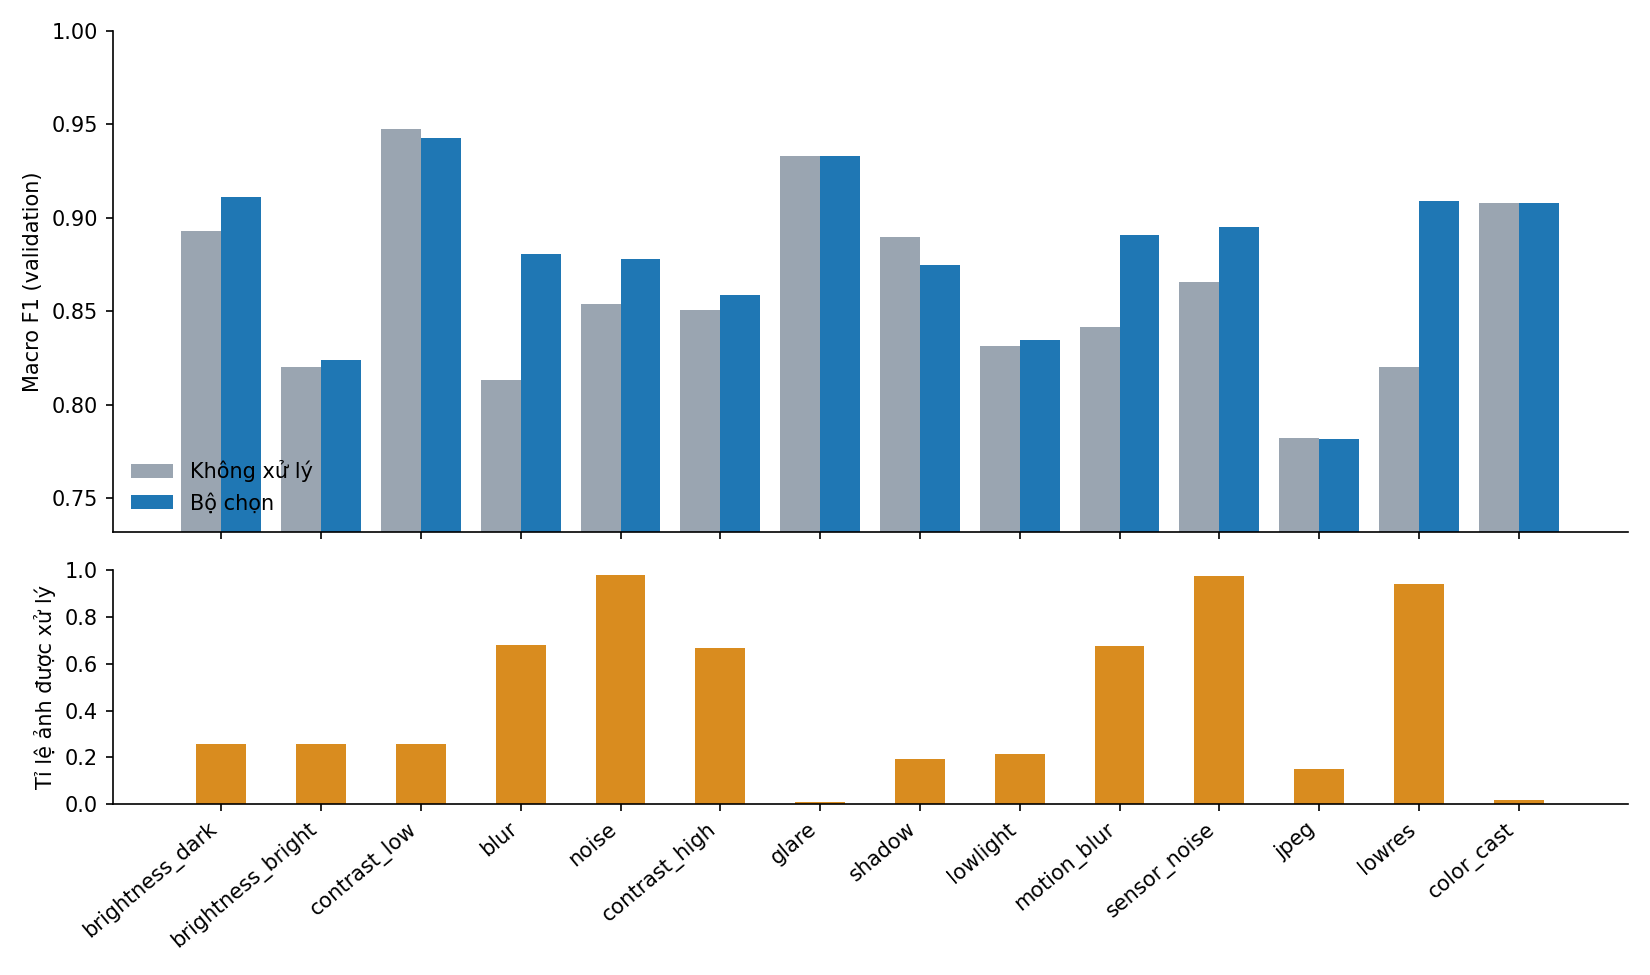

,f1_none,f1_selector,delta,trigger_rate
family,,,,
brightness_dark,0.8928,0.9109,0.0181,0.2575
brightness_bright,0.8200,0.8240,0.0040,0.2583
contrast_low,0.9476,0.9429,-0.0047,0.2583
blur,0.8130,0.8806,0.0677,0.6794
noise,0.8536,0.8781,0.0245,0.9782
contrast_high,0.8509,0.8589,0.0080,0.6667
glare,0.9330,0.9330,0.0000,0.0083
shadow,0.8895,0.8746,-0.0150,0.1922
lowlight,0.8313,0.8346,0.0033,0.2162


In [7]:
plot_by_family(frame, REP / "selector_by_family.png")
display(Image(filename=str(REP / "selector_by_family.png")))
display(frame[frame["condition"] != "clean"].groupby("family", sort=False)[["f1_none", "f1_selector", "delta", "trigger_rate"]].mean().round(4))

## 5. Lưu kết quả

Bộ chọn (`selector_calibrated.json`, `locked: false`), nhật ký tìm kiếm, bảng theo điều kiện và hình ghi vào `reports/selector/`. Bảng đặc trưng và dự đoán từng ảnh nằm trong output Kaggle, không đưa vào Git. Sau khi nhóm xem lại, đặt `locked: true` trong file bộ chọn và commit **trước khi** mở tập test ở task 6.1.

In [8]:
context = {
    "reference": reference, "checkpoint": cfg["checkpoint_name"], "corruption_config": cfg["corruption_config"],
    "images": int(len(table.labels)), "conditions": len(table.conditions) - 1, "actions": table.actions,
    "config_file": CONFIG, "commit": commit,
}
selector_path = save_artifacts(REP, selector, search_log, frame, summary, stability, cfg, context)
print(f"Đã ghi {selector_path}")
for path in sorted(REP.iterdir()):
    print(f"  {path.name} ({path.stat().st_size / 1024:.1f} KB)")

import zipfile

archive = Path("/kaggle/working/selector_outputs.zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for folder in (RES, REP):
        for path in sorted(folder.rglob("*")):
            if path.is_file():
                bundle.write(path, path.relative_to(REPO_DIR).as_posix())
print(f"Đã nén {archive} ({archive.stat().st_size / 1024**2:.1f} MB)")

Đã ghi /kaggle/working/durian-leaf-disease-robustness/reports/selector/selector_calibrated.json
  calibration_conditions_val.csv (5.5 KB)
  calibration_log.json (8.0 KB)
  selector_by_family.png (86.4 KB)
  selector_calibrated.json (1.3 KB)
Đã nén /kaggle/working/selector_outputs.zip (1.5 MB)
